<h1 style='text-align: center'><b><i>This is the notebook where Analysis Begins</i><b></h1>

#### **Major question**

> **Did economic ouput and income per person increase, and what can we reasonably infer about changes in people's material living standards?**

#### **Terms to get fimiliar with it first**

```text
1. GDP per capita vs GNI per capita
2. Inflation and purchasing power.
3. Population growth and per-capita measures
4. Mean, median, distribution and inequality 
```
Explaination of these terms we'll be added in `Terms_explainations.md` file

**[Terms_explainations.md](Terms_explainations.md)**

### **Required modules**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

### **Subquestion 1**

> How did **GDP per capita** change?

#### **Parameters**

1. **How much did GDP per capita increase overall?**
    - Calculate absolute change and percentage change between the endpoints for each period.

2. **At what annual rate did GDP per capita grow?**
    - Calculate CAGR for each ten-year period and compare the results.

3. **Did GDP per capita grow consistently?**
    - Examine annual growth rates to identify slowdowns, accelerations, and contractions.

4. **Was the increase real or mainly due to prices**?
    - Compare current-price GDP per capita with constant-price GDP per capita.

### **Let's define an `Ingestion` function.**

In [5]:
def ingestion(file_path: str) -> pd.DataFrame:
    """opent the file and return the dataframe"""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f'[CRITICAL] {file_path} does not exists')
    else:
        try:
            df = pd.read_parquet(file_path)
            print(f'[SUCCESS] file loaded containing {len(df)} rows')
        except Exception as e:
            print(f'[CRITICAL] Failed to load {file_path}: {e}')

    
    return df

#### **Data Ingestion for Subquestion 1**

In [6]:
# file path for our dataset.
file_path: str = 'cleaned_datasets/Production/df_ver01_production.parquet'

subq1_df: pd.DataFrame = ingestion(file_path=file_path)

subq1_df.head(10)

[SUCCESS] file loaded containing 21 rows


,Year,GDPPC(current US$),GDPPC(current LCU),GDPPC(constant 2015 US$),GDPPC_growth(annual %),GDPPC(constant LCU)
0,2004,624.258827,28048.906064,892.596615,6.099965,77946.373254
1,2005,710.488080,31455.781950,947.732566,6.177029,82761.143276
2,2006,801.668354,36275.092169,1008.232753,6.383677,88044.347518
3,2007,1021.887077,41141.855321,1069.246968,6.051600,93372.439372
4,2008,992.519585,45649.565654,1086.506053,1.614135,94879.596145
5,2009,1094.949746,51948.412516,1155.101633,6.313410,100869.733922
6,2010,1347.519391,61395.941246,1235.159391,6.930798,107860.811225
7,2011,1445.461275,69268.600210,1281.610544,3.760742,111917.177550
8,2012,1429.321995,77768.134804,1333.096266,4.017267,116413.189792
9,2013,1432.843975,86689.811555,1399.453798,4.977700,122207.889108


### **Parameter 1: How much does GDP per capita increase overall**

- Calculate absolute change and percentage change between the endpoints for each period.

| | **Starts** | **Ends** |
|-|------------|----------|
| **Period 1** | 2004 | 2014 |
| **Period 2** | 2014 | 2024 |

In [8]:
# Let's find out GDPPC for these years.
years: list = [2004, 2014, 2024]

# GDPPC (current US$)
gdppc_current_us: dict = {}

# GDPPC (current LCU)
gdppc_current_lcu: dict = {}

# GDPPC (constant US$) 
gdppc_constant_us: dict = {}

# GDPPC (constant LCU)
gdppc_constant_lcu: dict = {}

for year in years:
    gdppc_cur_us = subq1_df[subq1_df['Year']==year]['GDPPC(current US$)'].item()
    gdppc_cur_lcu = subq1_df[subq1_df['Year']==year]['GDPPC(current LCU)'].item()
    gdppc_cons_us = subq1_df[subq1_df['Year']==year]['GDPPC(constant 2015 US$)'].item()
    gdppc_cons_lcu = subq1_df[subq1_df['Year']==year]['GDPPC(constant LCU)'].item()

    # let's assign them inside their dictionaries.
    gdppc_current_us[year] = gdppc_cur_us
    gdppc_current_lcu[year] = gdppc_cur_lcu
    gdppc_constant_us[year] = gdppc_cons_us
    gdppc_constant_lcu[year] = gdppc_cons_lcu

In [63]:
# Periods 
periods: list = [
    [2004, 2014],
    [2014, 2024]
]

per_no = 1

# calculated data
calculated_data: dict = {}
for period in periods:
    # Absolute increase in GDPPC (current US$) 
    abs_inc_cur_us = gdppc_current_us[period[1]] - gdppc_current_us[period[0]]
    # Absolute increase in GDPPC (current LCU)
    abs_inc_cur_lcu = gdppc_current_lcu[period[1]] - gdppc_current_lcu[period[0]]
    # Absolute increase in GDPPC (constant 2015 US$)
    abs_inc_cons_us = gdppc_constant_us[period[1]] - gdppc_constant_us[period[0]]
    # Absolute increase in GDPPC (constant LCU)
    abs_inc_cons_lcu = gdppc_constant_lcu[period[1]] - gdppc_constant_lcu[period[0]]


    # Percentage increase in GDPPC (current US$)
    per_inc_cur_us = ((gdppc_current_us[period[1]] - gdppc_current_us[period[0]]) /  gdppc_current_us[period[0]]) * 100 
    # Percentage increase in GDPPC (current LCU)
    per_inc_cur_lcu = ((gdppc_current_lcu[period[1]] - gdppc_current_lcu[period[0]]) /  gdppc_current_lcu[period[0]]) * 100 
    # Percentage increase in GDPPC (constant 2015 US$)
    per_inc_cons_us = ((gdppc_constant_us[period[1]] - gdppc_constant_us[period[0]]) /  gdppc_constant_us[period[0]]) * 100 
    # Percentage increase in GDPPC (constant LCU)
    per_inc_cons_lcu = ((gdppc_constant_lcu[period[1]] - gdppc_constant_lcu[period[0]]) /  gdppc_constant_lcu[period[0]]) * 100 

    # Assigning that datapoint to calculated data dictionary
    calculated_data[f'Period {per_no}'] = {
        'abs_inc_current_US$' : abs_inc_cur_us,
        'abs_inc_current_LCU(₹)': abs_inc_cur_lcu,
        'abs_inc_constant_2015_US$' : abs_inc_cons_us,
        'abs_inc_constant_LCU(₹)': abs_inc_cons_lcu,
        '%_inc_current_US$' : per_inc_cur_us,
        '%_inc_current_LCU(₹)' : per_inc_cur_lcu,
        '%_inc_constant_2015_US$' : per_inc_cons_us,
        '%_inc_constant_LCU(₹)': per_inc_cons_lcu
    }

    per_no = 2

# Let's convert the findings into a new dataframe.
gddppc_df = pd.DataFrame(calculated_data)

# we have calculated these figures from unrounded value but it would be better
# if we round the result.
gddppc_df['Period 1'] = gddppc_df['Period 1'].round(2)
gddppc_df['Period 2'] = gddppc_df['Period 2'].round(2)

gddppc_df

,Period 1,Period 2
abs_inc_current_US$,929.63,1038.11
abs_inc_current_LCU(₹),66961.20,124209.17
abs_inc_constant_2015_US$,591.72,882.52
abs_inc_constant_LCU(₹),51672.18,77066.12
%_inc_current_US$,148.92,66.81
%_inc_current_LCU(₹),238.73,130.73
%_inc_constant_2015_US$,66.29,59.46
%_inc_constant_LCU(₹),66.29,59.46


In [64]:
gddppc_df = gddppc_df.T

gddppc_df = gddppc_df.reset_index()

In [65]:
# renaming the index columns.
gddppc_df = gddppc_df.rename(columns={'index': 'periods'})

gddppc_df

,periods,abs_inc_current_US$,abs_inc_current_LCU(₹),abs_inc_constant_2015_US$,abs_inc_constant_LCU(₹),%_inc_current_US$,%_inc_current_LCU(₹),%_inc_constant_2015_US$,%_inc_constant_LCU(₹)
0,Period 1,929.63,66961.20,591.72,51672.18,148.92,238.73,66.29,66.29
1,Period 2,1038.11,124209.17,882.52,77066.12,66.81,130.73,59.46,59.46


### **Parameter 2 - At what annual rate did GDP per capita grow?**

- Calculate **CAGR** for each ten-year period and compare the results.

The formula:
> **(((Ending value / Beginning value) ^ 1/n) - 1) * 100**

In [12]:
# CAGR of GDP per capita (constant 2015 US$)
cagr_period_1 = (((gdppc_constant_us[2014] / gdppc_constant_us[2004]) ** (1 / 10)) - 1) * 100
cagr_period_2 = (((gdppc_constant_us[2024] / gdppc_constant_us[2014]) ** (1 / 10)) - 1) * 100

print(f'CAGR of GDP per capita (constant 2015 US$):\nPeriod 1 -> {cagr_period_1:.2f}%\nPeriod 2 -> {cagr_period_2:.2f}%')

CAGR of GDP per capita (constant 2015 US$):
Period 1 -> 5.22%
Period 2 -> 4.78%


### **Parameter 3 - Did GDP per capita grow consistently?**

- Examining annual growth rates to identify slowdowns, accelerations, and contractions.

**Via visualizing with help of a line plot**

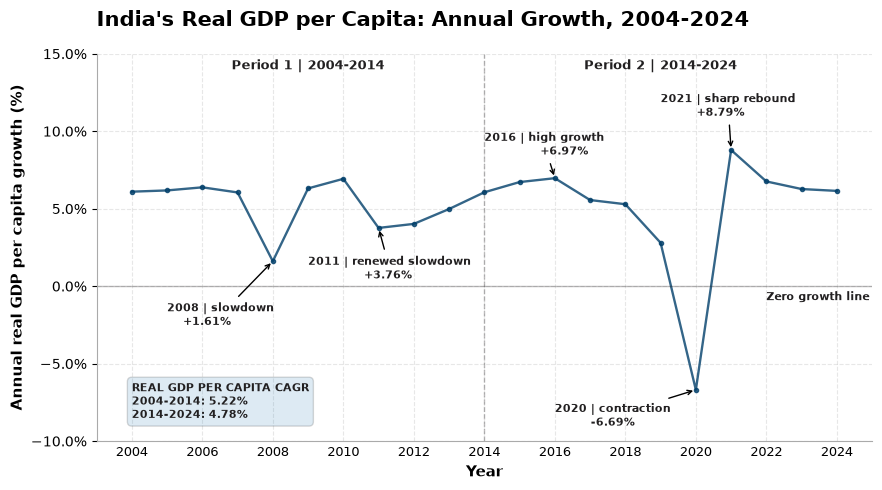

In [13]:
from matplotlib.ticker import PercentFormatter # percentage labels

# years would be on x axis
x_axis = subq1_df['Year']
# GDPPC annual growth (%) rounded value, would be on y axis
y_axis = subq1_df['GDPPC_growth(annual %)'].round(2)

# initiating figure and axes
fig, ax = plt.subplots(figsize=(9, 5))

# Plotting
ax.plot(
    x_axis,
    y_axis,
    marker='o',
    markersize= 3,
    linewidth=1.7,
    color='#013F6A',
    alpha=0.8
)

# titles and labels
ax.set_title("India's Real GDP per Capita: Annual Growth, 2004-2024", fontsize=15, fontweight='bold', loc='left', pad=20)
ax.set_xlabel('Year', fontsize=11, fontweight='bold')
ax.set_ylabel('Annual real GDP per capita growth (%)', fontsize=11, fontweight='bold')

# ticks and tick labels.
ax.set_ylim(-10, 15)
ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)
ax.tick_params(axis='x', which='major', labelsize=9.5, length=0)
ax.set_xticks([2004, 2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])

# spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# grids
ax.grid(axis='both', alpha=0.3, linestyle='--')

# vertical line on 2014 refrence the transition year.
ax.axvline(
    2014,
    linestyle='--',
    linewidth=1,
    alpha=0.3,
    color='#222021'
)

# Horizontal line on 0.0% refrence the zero growth line.
ax.axhline(
    0.0,
    linestyle='-',
    linewidth=1,
    alpha=0.3,
    color='#222021'
)

# text for zero growth
ax.text(
    2022,
    -0.9,
    'Zero growth line',
    fontsize=8,
    fontweight='bold',
    color='#222021'
)

# period text
ax.text(
    2009,
    14,
    f'Period 1 | 2004-2014',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center'
)
ax.text(
    2019,
    14,
    f'Period 2 | 2014-2024',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center'
)

# Annotations
ax.annotate(
    f'REAL GDP PER CAPITA CAGR\n2004-2014: {cagr_period_1:.2f}%\n2014-2024: {cagr_period_2:.2f}%',
    xy=(2004, -5.0),
    xytext=(2004, -8.5),
    fontsize=8,
    fontweight='bold',
    color= '#222021',
    bbox=dict(boxstyle='round,pad=0.4', alpha=0.15),
)

ax.annotate(
    f'2008 | slowdown\n    +{subq1_df[subq1_df['Year']==2008]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2008, subq1_df[subq1_df['Year']==2008]['GDPPC_growth(annual %)'].item()),
    xytext=(2005, -2.5),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)
ax.annotate(
    f'2011 | renewed slowdown\n{' '*14}+{subq1_df[subq1_df['Year']==2011]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2011, subq1_df[subq1_df['Year']==2011]['GDPPC_growth(annual %)'].item()),
    xytext=(2009, 0.5),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)

ax.annotate(
    f'2016 | high growth\n{' '*14}+{subq1_df[subq1_df['Year']==2016]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2016, subq1_df[subq1_df['Year']==2016]['GDPPC_growth(annual %)'].item()),
    xytext=(2014, 8.5),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)
ax.annotate(
    f'2020 | contraction\n{' '*9}{subq1_df[subq1_df['Year']==2020]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2020, subq1_df[subq1_df['Year']==2020]['GDPPC_growth(annual %)'].item()),
    xytext=(2016, -9.),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)
ax.annotate(
    f'2021 | sharp rebound\n{' '*9}+{subq1_df[subq1_df['Year']==2021]['GDPPC_growth(annual %)'].item():.2f}%',
    xy=(2021, subq1_df[subq1_df['Year']==2021]['GDPPC_growth(annual %)'].item()),
    xytext=(2019, 11),
    fontsize=8,
    fontweight='bold',
    color='#222021',
    arrowprops=dict(arrowstyle='->')
)


plt.tight_layout()
plt.show()


### **Parameter 4 - Was the increase real or mainly due to prices**?
- Comparing current-price GDP per capita with constant-price GDP per capita.

Again **visualizing with the help of a line plot**

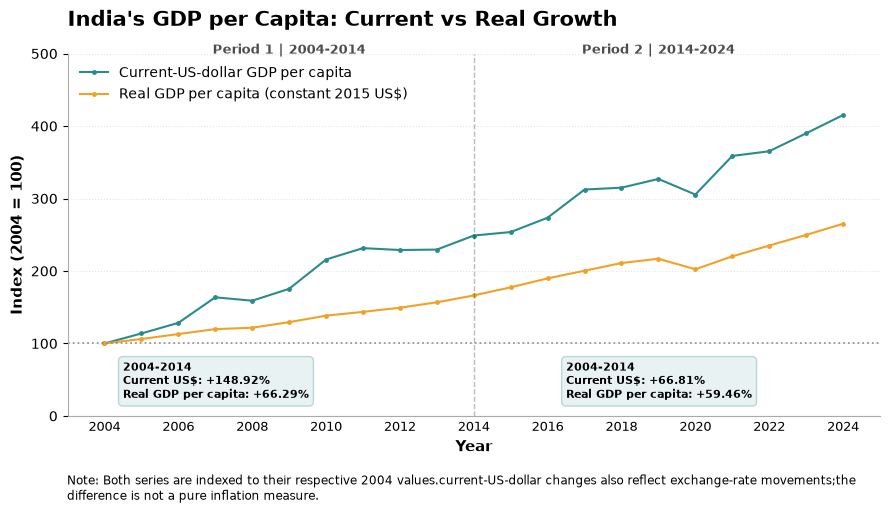

In [70]:
nominal_gddppc = list(((subq1_df['GDPPC(current US$)'] / subq1_df[subq1_df['Year'] == 2004]['GDPPC(current US$)'].item()) * 100).round(2))
real_gddpc = list(((subq1_df['GDPPC(constant 2015 US$)'] / subq1_df[subq1_df['Year'] == 2004]['GDPPC(constant 2015 US$)'].item()) * 100).round(2))
year = subq1_df['Year']
# Initiating figure and axes.
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    year,
    nominal_gddppc,
    marker='o',
    markersize=2.5,
    linewidth=1.5,
    label='Current-US-dollar GDP per capita',
    color='#298c8c'
)

ax.plot(
    year,
    real_gddpc,
    marker='o',
    markersize=2.5,
    linewidth=1.5,
    label='Real GDP per capita (constant 2015 US$)',
    color='#f1a226'
)

# titles and labels
ax.set_title("India's GDP per Capita: Current vs Real Growth", fontsize=15, fontweight='bold', pad=20, loc='left')
ax.set_xlabel('Year', fontsize=11, fontweight='bold')
ax.set_ylabel('Index (2004 = 100)', fontsize=11, fontweight='bold')

# ticks and ticklabels
ax.set_ylim(0, 500)
ax.tick_params(axis='x', which='major', labelsize=9.5, length=0)
ax.set_xticks(range(2004, 2025, 2))
# grid
ax.grid(axis='y', linestyle=':', alpha=0.35)
ax.grid(axis='x', visible=False)
# spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#aaaaaa')
ax.spines['bottom'].set_color('#aaaaaa')

# vertical line on 2014 represent Transitional year.
ax.axvline(
    2014,
    linestyle='--',
    linewidth=1,
    alpha=0.3,
    color='#222021'
)

# Baseline: each series equals 100 in 2004.
ax.axhline(
    y=100,
    color="gray",
    linestyle=":",
    linewidth=1.3,
    alpha=0.8
)

current_p1 = gddppc_df[gddppc_df['periods']=='Period 1']['%_inc_current_US$'].item()
current_p2 = gddppc_df[gddppc_df['periods']=='Period 2']['%_inc_current_US$'].item()
real_p1 = gddppc_df[gddppc_df['periods']=='Period 1']['%_inc_constant_2015_US$'].item()
real_p2 = gddppc_df[gddppc_df['periods']=='Period 2']['%_inc_constant_2015_US$'].item()
# PERIOD SUMMARY BOXES
ax.text(
    2004.5,
    25,
    f'2004-2014\n'
    f'Current US$: +{current_p1:.2f}%\n'
    f'Real GDP per capita: +{real_p1:.2f}%',
    fontsize=8,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.4',
        facecolor='#E8F2F3',
        edgecolor='#B8D4D5',
        alpha=0.95
    )
)
ax.text(
    2016.5,
    25,
    f'2004-2014\n'
    f'Current US$: +{current_p2:.2f}%\n'
    f'Real GDP per capita: +{real_p2:.2f}%',
    fontsize=8,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.4',
        facecolor='#E8F2F3',
        edgecolor='#B8D4D5',
        alpha=0.95
    )
)

ax.text(
    2009,
    500,
    'Period 1 | 2004-2014',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center',
    alpha=0.8
)
ax.text(
    2019,
    500,
    'Period 2 | 2014-2024',
    fontsize=9,
    fontweight='bold',
    color='#222021',
    ha='center',
    alpha=0.8
)

# Footer
fig.text(
    0.08,
    -0.01,
    "Note: Both series are indexed to their respective 2004 values."
    "current-US-dollar changes also reflect exchange-rate movements;"
    "the\ndifference is not a pure inflation measure.",
    fontsize=8.5
    
)

ax.legend(frameon=False, loc='upper left')
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()